# 提高任务：CBOW 与 Skip-gram 对比

此文件可独立从头运行。前半部分沿用老师的原始语料和 Skip-gram 代码，后半部分实现 CBOW。两者使用窗口1、10维词向量、Adam、学习率0.03和1000轮训练。

CBOW 对有效上下文词向量取平均，使用完整 Softmax。负采样、层次 Softmax 与哈夫曼树按老师要求进行书面讨论，本文件未实现这些算法。

本仓库中的输出由整理项目时重新运行生成，生成文件保存在仓库根目录的 `results/` 下。课程原实验报告位于 `report/`，其中 CBOW 只记录样本构造；本 Notebook 进一步训练了 CBOW，属于扩展实验。


## 1. 准备原始语料


In [1]:
sentences = [
    "猫 喜欢 吃 鱼",
    "狗 喜欢 吃 肉",
    "猫 和 狗 都 是 宠物",
    "小猫 是 可爱 的 宠物",
    "小狗 是 忠诚 的 宠物",
    "鱼 生活 在 水中",
    "鸟 喜欢 在 天空 飞翔",
    "飞机 在 天空 飞行",
]

corpus = " ".join(sentences).split()
print("语料词数：", len(corpus))
print("前20个词：", corpus[:20])

语料词数： 37
前20个词： ['猫', '喜欢', '吃', '鱼', '狗', '喜欢', '吃', '肉', '猫', '和', '狗', '都', '是', '宠物', '小猫', '是', '可爱', '的', '宠物', '小狗']


## 2. 建立词表


In [2]:
from collections import Counter

word_counts = Counter(corpus)
vocab = sorted(word_counts, key=word_counts.get, reverse=True)
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

print("词表大小：", len(vocab))
print("词表：", vocab)


词表大小： 23
词表： ['喜欢', '是', '宠物', '在', '猫', '吃', '鱼', '狗', '的', '天空', '肉', '和', '都', '小猫', '可爱', '小狗', '忠诚', '生活', '水中', '鸟', '飞翔', '飞机', '飞行']


## 3. 构造 Skip-gram 样本


In [3]:
def make_skipgram_pairs(tokens, word_to_id, window_size=1):
    pairs = []
    for center_pos, center_word in enumerate(tokens):
        center_id = word_to_id[center_word]
        left = max(0, center_pos - window_size)
        right = min(len(tokens), center_pos + window_size + 1)

        for context_pos in range(left, right):
            if context_pos == center_pos:
                continue
            context_word = tokens[context_pos]
            pairs.append((center_id, word_to_id[context_word]))
    return pairs

sentence_tokens = [sentence.split() for sentence in sentences]
pairs = [pair for tokens in sentence_tokens
         for pair in make_skipgram_pairs(tokens, word_to_id, window_size=1)]

print("训练样本数：", len(pairs))
for center_id, context_id in pairs[:10]:
    print(id_to_word[center_id], "→", id_to_word[context_id])

训练样本数： 58
猫 → 喜欢
喜欢 → 猫
喜欢 → 吃
吃 → 喜欢
吃 → 鱼
鱼 → 吃
狗 → 喜欢
喜欢 → 狗
喜欢 → 吃
吃 → 喜欢


## 4. 导入 PyTorch


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim

torch.set_num_threads(1)
torch.manual_seed(42)

Out[1]: <torch._C.Generator at 0x1cace2ffb70>


## 5. 定义 Skip-gram 模型


In [5]:
class SkipGram(nn.Module):
    def __init__(self, vocab_size, embedding_dim=10):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, center_words):
        vectors = self.embedding(center_words)
        logits = self.output(vectors)
        return logits


## 6. 准备 Skip-gram 张量


In [6]:
centers = torch.tensor([p[0] for p in pairs], dtype=torch.long)
contexts = torch.tensor([p[1] for p in pairs], dtype=torch.long)

print("中心词张量形状：", centers.shape)
print("上下文词张量形状：", contexts.shape)

中心词张量形状： torch.Size([58])
上下文词张量形状： torch.Size([58])


## 7. 训练 Skip-gram


In [7]:
embedding_dim = 10
model = SkipGram(len(vocab), embedding_dim=embedding_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.03)

loss_history = []

for epoch in range(1000):
    optimizer.zero_grad()
    logits = model(centers)
    loss = criterion(logits, contexts)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 200 == 0:
        print(f"epoch={epoch + 1}, loss={loss.item():.4f}")

epoch=200, loss=0.9814
epoch=400, loss=0.9808
epoch=600, loss=0.9806
epoch=800, loss=0.9805
epoch=1000, loss=0.9805


## CBOW 1. 构造 CBOW 样本


In [8]:
def make_cbow_samples(tokens, word_to_id, window_size=1):
    samples = []
    for center_pos, center_word in enumerate(tokens):
        center_id = word_to_id[center_word]
        left = max(0, center_pos - window_size)
        right = min(len(tokens), center_pos + window_size + 1)

        context_ids = []
        for context_pos in range(left, right):
            if context_pos != center_pos:
                context_ids.append(word_to_id[tokens[context_pos]])

        if context_ids:
            samples.append((context_ids, center_id))
    return samples

cbow_samples = [sample for tokens in sentence_tokens
                for sample in make_cbow_samples(tokens, word_to_id, window_size=1)]

print("CBOW训练样本数：", len(cbow_samples))
for context_ids, center_id in cbow_samples[:10]:
    context_words = [id_to_word[i] for i in context_ids]
    print(context_words, "→", id_to_word[center_id])



CBOW训练样本数： 37
['喜欢'] → 猫
['猫', '吃'] → 喜欢
['喜欢', '鱼'] → 吃
['吃'] → 鱼
['喜欢'] → 狗
['狗', '吃'] → 喜欢
['喜欢', '肉'] → 吃
['吃'] → 肉
['和'] → 猫
['猫', '狗'] → 和


## CBOW 2. 准备训练张量


In [9]:
max_context_size = max(len(context_ids) for context_ids, _ in cbow_samples)
cbow_contexts = torch.zeros((len(cbow_samples), max_context_size), dtype=torch.long)
cbow_mask = torch.zeros((len(cbow_samples), max_context_size), dtype=torch.float32)
cbow_centers = torch.tensor([center_id for _, center_id in cbow_samples], dtype=torch.long)

for i, (context_ids, _) in enumerate(cbow_samples):
    context_size = len(context_ids)
    cbow_contexts[i, :context_size] = torch.tensor(context_ids, dtype=torch.long)
    cbow_mask[i, :context_size] = 1.0

print("上下文张量形状：", cbow_contexts.shape)
print("掩码张量形状：", cbow_mask.shape)
print("中心词张量形状：", cbow_centers.shape)



上下文张量形状： torch.Size([37, 2])
掩码张量形状： torch.Size([37, 2])
中心词张量形状： torch.Size([37])


## CBOW 3. 定义 CBOW 模型


In [10]:
class CBOW(nn.Module):
    def __init__(self, vocab_size, embedding_dim=10):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, context_words, context_mask):
        vectors = self.embedding(context_words)
        mask = context_mask.unsqueeze(-1)
        mean_vectors = (vectors * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        logits = self.output(mean_vectors)
        return logits



## CBOW 4. 训练 CBOW


In [11]:
torch.manual_seed(42)
cbow_model = CBOW(len(vocab), embedding_dim=10)
cbow_criterion = nn.CrossEntropyLoss()
cbow_optimizer = optim.Adam(cbow_model.parameters(), lr=0.03)
cbow_loss_history = []

for epoch in range(1000):
    cbow_optimizer.zero_grad()
    logits = cbow_model(cbow_contexts, cbow_mask)
    loss = cbow_criterion(logits, cbow_centers)
    loss.backward()
    cbow_optimizer.step()

    cbow_loss_history.append(loss.item())
    if (epoch + 1) % 200 == 0:
        print(f"epoch={epoch + 1}, loss={loss.item():.4f}")



epoch=200, loss=0.4182
epoch=400, loss=0.4165
epoch=600, loss=0.4161
epoch=800, loss=0.4160
epoch=1000, loss=0.4159


## CBOW 5. 绘制损失曲线


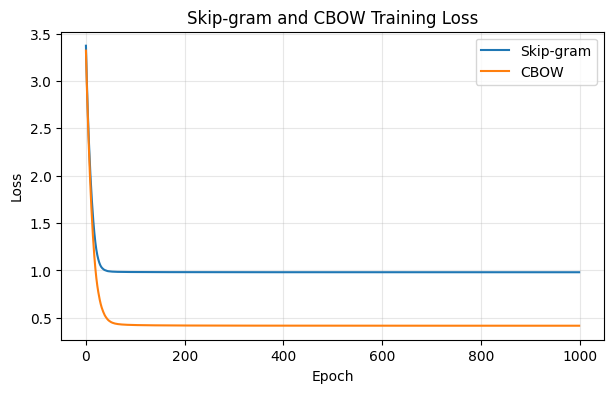

In [12]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("results").mkdir(exist_ok=True)
plt.figure(figsize=(7, 4))
plt.plot(loss_history, label="Skip-gram")
plt.plot(cbow_loss_history, label="CBOW")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Skip-gram and CBOW Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("results/extra_cbow_skipgram_loss.png", dpi=300, bbox_inches="tight")
plt.show()



## CBOW 6. 提取词向量并比较词对相似度


In [13]:
import pandas as pd
import torch.nn.functional as F

skipgram_embeddings = model.embedding.weight.detach()
cbow_embeddings = cbow_model.embedding.weight.detach()
print("Skip-gram词向量形状：", skipgram_embeddings.shape)
print("CBOW词向量形状：", cbow_embeddings.shape)

def vector_cosine_similarity(word_a, word_b, vectors):
    vec_a = vectors[word_to_id[word_a]].unsqueeze(0)
    vec_b = vectors[word_to_id[word_b]].unsqueeze(0)
    return F.cosine_similarity(vec_a, vec_b).item()

records = []
for word_a, word_b in [("猫", "狗"), ("天空", "飞机"), ("猫", "飞机"), ("鱼", "水中")]:
    records.append({
        "词对": f"{word_a}—{word_b}",
        "Skip-gram余弦相似度": vector_cosine_similarity(word_a, word_b, skipgram_embeddings),
        "CBOW余弦相似度": vector_cosine_similarity(word_a, word_b, cbow_embeddings),
    })

cbow_comparison = pd.DataFrame(records)
print(cbow_comparison.round(4).to_string(index=False))
cbow_comparison.to_csv("results/extra_cbow_skipgram_comparison.csv", index=False, encoding="utf-8-sig")



Skip-gram词向量形状： torch.Size([23, 10])
CBOW词向量形状： torch.Size([23, 10])
   词对  Skip-gram余弦相似度  CBOW余弦相似度
  猫—狗          0.7484     0.7133
天空—飞机          0.5342    -0.0305
 猫—飞机          0.3546     0.2399
 鱼—水中         -0.3721    -0.5928


## CBOW 7. 对比相似词


In [14]:
def model_most_similar(word, vectors, top_k=5):
    target_id = word_to_id[word]
    target = vectors[target_id].unsqueeze(0)
    similarities = F.cosine_similarity(target, vectors)

    result = []
    for idx in torch.argsort(similarities, descending=True):
        idx = idx.item()
        if idx == target_id:
            continue
        result.append((id_to_word[idx], float(similarities[idx])))
        if len(result) >= top_k:
            break
    return result

for word in ["猫", "狗", "天空", "宠物"]:
    print(f"{word} 的Skip-gram相似词：", model_most_similar(word, skipgram_embeddings))
    print(f"{word} 的CBOW相似词：", model_most_similar(word, cbow_embeddings))
    print()


猫 的Skip-gram相似词： [('狗', 0.7484437823295593), ('鸟', 0.4791223406791687), ('在', 0.44971176981925964), ('飞翔', 0.39766237139701843), ('飞行', 0.362668514251709)]
猫 的CBOW相似词： [('狗', 0.7133302688598633), ('飞翔', 0.45725879073143005), ('飞行', 0.438384085893631), ('在', 0.4067557156085968), ('宠物', 0.32511577010154724)]

狗 的Skip-gram相似词： [('猫', 0.7484437823295593), ('鸟', 0.3281325697898865), ('忠诚', 0.21707698702812195), ('飞翔', 0.20640970766544342), ('在', 0.17947092652320862)]
狗 的CBOW相似词： [('猫', 0.7133302688598633), ('宠物', 0.32876789569854736), ('忠诚', 0.3283790051937103), ('鸟', 0.3016778826713562), ('飞机', 0.2713458836078644)]

天空 的Skip-gram相似词： [('水中', 0.6922759413719177), ('飞机', 0.5342141389846802), ('鸟', 0.3054409623146057), ('生活', 0.2645106315612793), ('喜欢', 0.14344635605812073)]
天空 的CBOW相似词： [('水中', 0.5304909348487854), ('的', 0.3252204954624176), ('生活', 0.1731594353914261), ('吃', 0.1415705382823944), ('宠物', 0.09121604263782501)]

宠物 的Skip-gram相似词： [('可爱', 0.8576368689537048), ('忠诚', 0.72242790460

## 结果分析与书面讨论

记录实际输出，比较两种模型的词对相似度、相似词及各自损失下降趋势。两种预测目标和样本数不同，不应根据最终损失大小直接判断语义质量优劣。

请回答：CBOW如何合并多个上下文词向量？句首句尾如何处理？小语料与大语料下两种方法可能有什么差异？

根据课堂笔记说明完整Softmax的计算成本、负采样、层次Softmax以及哈夫曼树的频率加权路径设计。
